# 09 Calibration

**Question.** Notebook 04 checks whether each learner *ranks* users well (Qini). Here we check whether the *size* of the predicted uplift is right: when a model predicts an uplift of 2 points for a group of users, is the real uplift in that group about 2 points?

**Method.** Sort the held out users by predicted uplift and cut them into 10 groups of equal size (`uplift_by_decile`). In each group, the predicted uplift is the mean score and the observed uplift is the treated rate minus the control rate, which is unbiased because treatment was randomised. A perfectly calibrated model puts all 10 points on the diagonal.

**Summaries.** For each outcome and learner we fit a straight line of observed on predicted uplift across the 10 groups. The slope is the calibration slope: near 1 means the predictions are well scaled, below 1 means the model exaggerates the differences between groups, above 1 means it understates them. The Spearman correlation between the group number and the observed uplift checks the ordering alone: a good model gives a value near -1, because uplift should fall from group 1 to group 10.

The response baseline is left out: its scores are visit or conversion probabilities, not uplifts, so they cannot be compared with observed uplift.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
RESULTS = ROOT / "results"

from uplift.data import TREATMENT, OUTCOMES
from uplift import metrics as m

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NAMES = {"s": "S-learner", "t": "T-learner", "x": "X-learner"}
COLORS = {"s": "#1c7293", "t": "#f2a93b", "x": "#0b3d5c"}
s5 = pd.read_parquet(RESULTS / "scores_5m.parquet")
t = s5[TREATMENT].to_numpy()
print(f"{len(s5):,} held out users | outcomes: {OUTCOMES} | learners: {list(NAMES)}")

2,000,000 held out users | outcomes: ['visit', 'conversion'] | learners: ['s', 't', 'x']


## Predicted and observed uplift in each group

In [2]:
rows = []
for outcome in OUTCOMES:
    for mod in NAMES:
        d = m.uplift_by_decile(s5[outcome], t, s5[f"{mod}_{outcome}"], bins=10)
        rows.append(pd.DataFrame({"outcome": outcome, "model": mod, "decile": d["decile"],
                                  "mean_pred": d["mean_score"], "observed": d["uplift"], "se": d["se"],
                                  "ci_lo": d["uplift"] - 1.96 * d["se"], "ci_hi": d["uplift"] + 1.96 * d["se"]}))
calib = pd.concat(rows, ignore_index=True)
assert calib.shape == (60, 8) and calib.notna().all().all()
calib.round(6).to_csv(RESULTS / "calibration_5m.csv", index=False)
calib[calib.outcome == "visit"].round(5)

,outcome,model,decile,mean_pred,observed,se,ci_lo,ci_hi
0,visit,s,1,0.05583,0.06070,0.00279,0.05524,0.06616
1,visit,s,2,0.00921,0.00655,0.00207,0.00249,0.01060
2,visit,s,3,0.00300,0.00066,0.00113,-0.00155,0.00287
3,visit,s,4,0.00115,0.00161,0.00056,0.00051,0.00272
4,visit,s,5,0.00053,0.00029,0.00041,-0.00050,0.00109
5,visit,s,6,0.00035,0.00078,0.00029,0.00021,0.00135
6,visit,s,7,0.00018,0.00031,0.00022,-0.00012,0.00074
7,visit,s,8,0.00009,0.00024,0.00016,-0.00007,0.00055
8,visit,s,9,0.00006,0.00033,0.00010,0.00013,0.00052
9,visit,s,10,0.00000,0.00001,0.00036,-0.00070,0.00071


## Calibration slope and rank correlation

In [3]:
slopes = []
for (outcome, mod), g in calib.groupby(["outcome", "model"], sort=False):
    slope = np.polyfit(g["mean_pred"], g["observed"], 1)[0]
    rho = spearmanr(g["decile"], g["observed"]).statistic
    slopes.append(dict(outcome=outcome, model=mod, slope=slope, spearman=rho))
slopes = pd.DataFrame(slopes)
assert slopes.shape == (6, 4)
slopes.round(6).to_csv(RESULTS / "calibration_slopes_5m.csv", index=False)
slopes.round(3)

,outcome,model,slope,spearman
0,visit,s,1.086,-0.830
1,visit,t,0.878,-0.648
2,visit,x,1.016,-0.806
3,conversion,s,0.955,-0.636
4,conversion,t,0.588,-0.200
5,conversion,x,0.937,-0.430


## Calibration plot for visits

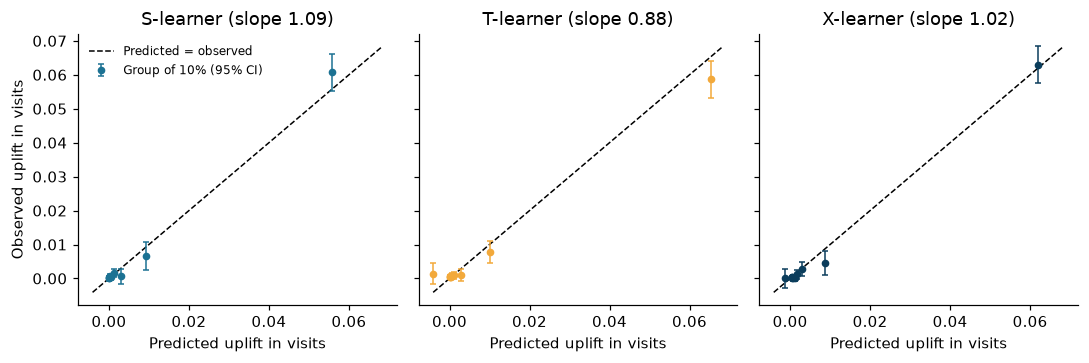

In [4]:
v = calib[calib.outcome == "visit"]
lo = min(v["mean_pred"].min(), v["ci_lo"].min()); hi = max(v["mean_pred"].max(), v["ci_hi"].max())
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharex=True, sharey=True)
for ax, mod in zip(axes, NAMES):
    g = v[v.model == mod]
    ax.plot([lo, hi], [lo, hi], "--", color="black", lw=1, label="Predicted = observed")
    ax.errorbar(g["mean_pred"], g["observed"], yerr=1.96 * g["se"], fmt="o", ms=4, color=COLORS[mod],
                ecolor=COLORS[mod], elinewidth=1, capsize=2, label="Group of 10% (95% CI)")
    sl = slopes.query("outcome == 'visit' and model == @mod")["slope"].item()
    ax.set_title(f"{NAMES[mod]} (slope {sl:.2f})"); ax.set_xlabel("Predicted uplift in visits")
axes[0].set_ylabel("Observed uplift in visits"); axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(RESULTS / "calibration_5m.png", dpi=200); plt.show()

## Conclusion

**How far to trust the slopes.** Most of the uplift sits in group 1, so that one point carries most of the weight in each fitted line. The table below shows, per outcome, how the typical observed uplift in a group compares with the half width of its 95 percent interval: when the interval is wider than the effect, most groups are noise and only the top group really informs the slope.

In [5]:
noise = (calib.assign(abs_obs=calib["observed"].abs(), half_ci=(calib["ci_hi"] - calib["ci_lo"]) / 2)
         .groupby("outcome", sort=False)[["abs_obs", "half_ci"]].median().mul(1000).round(3))
noise.columns = ["median |observed| per 1000", "median CI half width per 1000"]
noise

,median |observed| per 1000,median CI half width per 1000
outcome,,
visit,0.632,0.826
conversion,0.082,0.179


In [6]:
from IPython.display import Markdown
TOL = 0.1  # a slope within 0.1 of 1 counts as well scaled
sv = slopes[slopes.outcome == "visit"].set_index("model")
sc = slopes[slopes.outcome == "conversion"].set_index("model")
best = (sv["slope"] - 1).abs().idxmin()
def verdict(s):
    return "well scaled" if abs(s - 1) <= TOL else ("exaggerates the differences" if s < 1 else "understates the differences")
cv = calib[calib.outcome == "visit"].set_index(["model", "decile"])
tl = cv.loc[("t", 10)]
nc = noise.loc["conversion"]
Markdown(
    f"For visits the {NAMES[best]} is the best calibrated, with a slope of {sv.loc[best, 'slope']:.2f} "
    f"(S {sv.loc['s', 'slope']:.2f}, {verdict(sv.loc['s', 'slope'])}; "
    f"T {sv.loc['t', 'slope']:.2f}, {verdict(sv.loc['t', 'slope'])}; "
    f"X {sv.loc['x', 'slope']:.2f}, {verdict(sv.loc['x', 'slope'])}), while the T-learner exaggerates: its bottom group "
    f"is predicted at {tl['mean_pred'] * 1000:.1f} extra visits per 1000 users but shows {tl['observed'] * 1000:+.1f}. "
    f"For conversions the T-learner exaggerates most (slope {sc.loc['t', 'slope']:.2f}, against S {sc.loc['s', 'slope']:.2f} "
    f"and X {sc.loc['x', 'slope']:.2f}), but these slopes rest almost entirely on the top group, since the typical "
    f"group's observed conversion uplift ({nc.iloc[0]:.2f} per 1000) is smaller than its 95 percent interval half width ({nc.iloc[1]:.2f} per 1000)."
)

For visits the X-learner is the best calibrated, with a slope of 1.02 (S 1.09, well scaled; T 0.88, exaggerates the differences; X 1.02, well scaled), while the T-learner exaggerates: its bottom group is predicted at -4.1 extra visits per 1000 users but shows +1.4. For conversions the T-learner exaggerates most (slope 0.59, against S 0.95 and X 0.94), but these slopes rest almost entirely on the top group, since the typical group's observed conversion uplift (0.08 per 1000) is smaller than its 95 percent interval half width (0.18 per 1000).